<img src="https://ga-curriculum.github.io/universal-resources-internal/ga-logos/ga-red-cog-72x72.png" alt="" style="float: left; margin: 20px 20px 0 0; height: 55px">

# Continuous Distributions

_Author:_ Tim Book

In [51]:
# The usual imports... plus a new one!
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
import seaborn as sns

## `scipy.stats`
SciPy is a scientific computing library. It contains various functions for matrix algebra, calculus, statistics, and probability. The `stats` submodule is what we'll need today!

## The Normal Distribution
Let's create a normal random variable! Let's arbitrarily pick mean 7 and standard deviation 2

In [5]:
X = stats.norm(7, 2)

Let's sample some observations from $X$ and plot. What happens when we increase $n$?

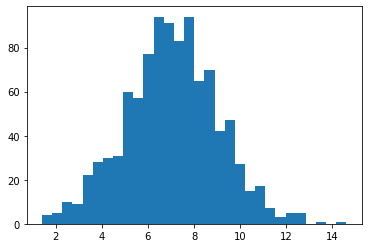

In [41]:
n = 1000
xs = X.rvs(n)

plt.hist(xs, bins=30);

## Let's pick another one!
Pick a different distribution and plot. Maybe exponential? Let's plot density plots for various $\beta$s

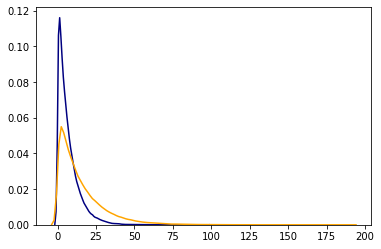

In [57]:
n = 100000
X1 = stats.expon(scale=7)
x1s = X1.rvs(n)

X2 = stats.expon(scale=15)
x2s = X2.rvs(n)

sns.kdeplot(x1s, color='navy')
sns.kdeplot(x2s, color='orange');

In [58]:
x1s.mean()

7.01946005612596

In [59]:
x2s.mean()

14.947627901813455

## Demo of the Empirical Rule
Let's sample a zillion observations from a standard normal.

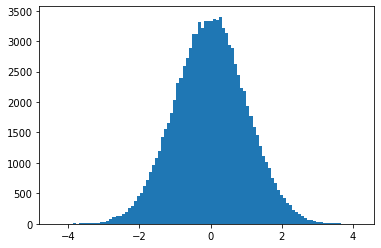

In [62]:
Z = stats.norm(0, 1)
zs = Z.rvs(100_000)
plt.hist(zs, bins=100);

What proportion of these samples are between -1 and 1? -2 and 2? -3 and 3?

In [63]:
np.mean((zs > -1) & (zs < 1))

0.68266

In [64]:
np.mean((zs > -2) & (zs < 2))

0.68266

In [65]:
np.mean((zs > -3) & (zs < 3))

0.99757

## Calculating probabilities with CDFs

### Problem 1
Suppose every morning you wait for the bus. Buses in your area come about ever 15 minutes. What's the probability you'll be waiting for more than 20?

In [66]:
W = stats.expon(scale=15)

In [69]:
1 - W.cdf(20)

0.2635971381157267

### Problem 2
Suppose $X \sim N(7, 2)$. What is $P(5.5 \le X \le 7.3)$?

In [72]:
X = stats.norm(7, 2)
a = 5.5
b = 7.3

X.cdf(b) - X.cdf(a)

0.3329903399933743

### BONUS Problem 3
Suppose:

* $X \sim \text{Exp}(\beta = 5)$
* $Y \sim U(0, 10)$
* $Z \sim N(0, 1)$

And they're all mutually independent.

In [73]:
# Define X, Y, Z here:
X = stats.expon(scale=5)
Y = stats.uniform(0, 10)
Z = stats.norm(0, 1)

#### 3a
What is $P(X > 3 \cap Y < 8 \cap Z > 1.5)$?

_Reminder:_ The $\cap$ symbol means "and"

In [74]:
p1 = 1 - X.cdf(3)
p2 = Y.cdf(8)
p3 = 1 - Z.cdf(1.5)

p1*p2*p3

0.029331655544979938

#### 3b
What is $P(X > 3 \cup Y < 8)$?

_Reminder:_ The $\cup$ symbol means "or"

In [75]:
p1 = 1 - X.cdf(3)
p2 = Y.cdf(8)

p1 + p2 - p1*p2

0.9097623272188051

#### 3c (a multistep problem!)

What is $P(X > 3 \cap (Y < 8 \cup Z > 1.5)$?

In [77]:
p1 = 1 - X.cdf(3)
p2 = Y.cdf(8)
p3 = 1 - Z.cdf(1.5)

a = p1
b = p2 + p3 - p2*p3

ans = a*b
ans

0.4463822227614661